# Clasificación de flores con PyTorch Lightning

Ejemplo reproducible de clasificación de imágenes con una CNN pequeña entrenada desde cero en CPU.
Dataset público `flower_photos` (5 clases). El objetivo es validar el entorno y el flujo, no maximizar la exactitud.

Ejecutar con `data-science/.venv`, con el directorio de trabajo en `data-science/`.

In [1]:
import warnings
from pathlib import Path

import lightning as L
import torch

# Avisos conocidos y benignos de Lightning; el resto de avisos se siguen mostrando.
# - num_workers: el plan fija num_workers=0 a propósito (sin procesos hijo en el notebook).
# - LeafSpec: deprecación interna de Lightning con la versión de torch fijada; no depende de este código.
warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message=".*isinstance\(treespec, LeafSpec\).*")

SEED = 42
DATA_DIR = Path("data")
DATASET_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
IMG_SIZE = 96
BATCH_SIZE = 32
MAX_EPOCHS = 3
PACIENCIA = 5  # épocas sin mejorar perdida_val antes de que EarlyStopping detenga el entrenamiento

L.seed_everything(SEED, workers=True)
DEVICE = torch.device("cpu")
print(f"torch {torch.__version__} | lightning {L.__version__} | dispositivo: {DEVICE}")

<>:11: SyntaxWarning: invalid escape sequence '\('
<>:11: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_15168/1902512380.py:11: SyntaxWarning: invalid escape sequence '\('
  warnings.filterwarnings("ignore", message=".*isinstance\(treespec, LeafSpec\).*")


Seed set to 42


torch 2.14.1+cpu | lightning 2.6.6 | dispositivo: cpu


In [2]:
import tarfile
import urllib.request

ARCHIVE = DATA_DIR / "flower_photos.tgz"
FLOWERS_DIR = DATA_DIR / "flower_photos"


def descargar_flores() -> Path:
    """Descarga y extrae flower_photos (público, sin credenciales). Reutiliza el dataset si ya existe."""
    if FLOWERS_DIR.is_dir() and any(FLOWERS_DIR.glob("*/*.jpg")):
        return FLOWERS_DIR
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    if not ARCHIVE.exists():
        print(f"Descargando {DATASET_URL}")
        urllib.request.urlretrieve(DATASET_URL, ARCHIVE)
    with tarfile.open(ARCHIVE) as tar:
        tar.extractall(DATA_DIR, filter="data")
    return FLOWERS_DIR


FLOWERS_DIR = descargar_flores()
CLASES = sorted(p.name for p in FLOWERS_DIR.iterdir() if p.is_dir())
print(f"{len(CLASES)} clases: {CLASES}")
for clase in CLASES:
    print(f"  {clase}: {len(list((FLOWERS_DIR / clase).glob('*.jpg')))} imágenes")

5 clases: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
  daisy: 633 imágenes
  dandelion: 898 imágenes
  roses: 641 imágenes
  sunflowers: 699 imágenes
  tulips: 799 imágenes


In [3]:
import random

from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.io import ImageReadMode, decode_image

MEDIA, DESVIACION = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


class ImagenesFlores(Dataset):
    """Pares (imagen, clase) a partir de una lista de rutas; la clase es el nombre de la carpeta padre."""

    def __init__(self, rutas: list[Path], transformacion) -> None:
        self.rutas = rutas
        self.transformacion = transformacion

    def __len__(self) -> int:
        return len(self.rutas)

    def __getitem__(self, i: int):
        ruta = self.rutas[i]
        imagen = decode_image(str(ruta), mode=ImageReadMode.RGB)
        return self.transformacion(imagen), CLASES.index(ruta.parent.name)


def dividir_rutas(directorio: Path, semilla: int, fraccion_val: float = 0.2) -> tuple[list[Path], list[Path]]:
    """Divide por clase de forma estratificada y reproducible: misma semilla, misma división."""
    azar = random.Random(semilla)
    entrenamiento, validacion = [], []
    for clase in sorted(p.name for p in directorio.iterdir() if p.is_dir()):
        rutas = sorted((directorio / clase).glob("*.jpg"))
        azar.shuffle(rutas)
        corte = int(len(rutas) * fraccion_val)
        validacion += rutas[:corte]
        entrenamiento += rutas[corte:]
    return entrenamiento, validacion


class FloresDataModule(L.LightningDataModule):
    def __init__(self, directorio: Path = FLOWERS_DIR, tamano: int = IMG_SIZE, lote: int = BATCH_SIZE, semilla: int = SEED) -> None:
        super().__init__()
        self.directorio, self.lote, self.semilla = directorio, lote, semilla
        base = [transforms.Resize((tamano, tamano), antialias=True), transforms.ConvertImageDtype(torch.float32)]
        self.t_entrenamiento = transforms.Compose(base + [transforms.RandomHorizontalFlip(), transforms.Normalize(MEDIA, DESVIACION)])
        self.t_validacion = transforms.Compose(base + [transforms.Normalize(MEDIA, DESVIACION)])

    def prepare_data(self) -> None:
        descargar_flores()

    def setup(self, stage: str | None = None) -> None:
        self.rutas_entrenamiento, self.rutas_validacion = dividir_rutas(self.directorio, self.semilla)
        self.ds_entrenamiento = ImagenesFlores(self.rutas_entrenamiento, self.t_entrenamiento)
        self.ds_validacion = ImagenesFlores(self.rutas_validacion, self.t_validacion)

    def train_dataloader(self) -> DataLoader:
        generador = torch.Generator().manual_seed(self.semilla)
        return DataLoader(self.ds_entrenamiento, batch_size=self.lote, shuffle=True, num_workers=0, generator=generador)

    def val_dataloader(self) -> DataLoader:
        return DataLoader(self.ds_validacion, batch_size=self.lote, shuffle=False, num_workers=0)


datos = FloresDataModule()
datos.prepare_data()
datos.setup()
print(f"entrenamiento: {len(datos.rutas_entrenamiento)} imágenes | validación: {len(datos.rutas_validacion)} imágenes")
x, y = next(iter(datos.train_dataloader()))
print(f"lote: imágenes {tuple(x.shape)} {x.dtype} | etiquetas {tuple(y.shape)}")

entrenamiento: 2939 imágenes | validación: 731 imágenes
lote: imágenes (32, 3, 96, 96) torch.float32 | etiquetas (32,)


In [4]:
import torch.nn.functional as F
from torch import nn
from torchmetrics.classification import MulticlassAccuracy


def bloque(entrada: int, salida: int) -> nn.Sequential:
    return nn.Sequential(nn.Conv2d(entrada, salida, 3, padding=1), nn.BatchNorm2d(salida), nn.ReLU(), nn.MaxPool2d(2))


class CnnFlores(L.LightningModule):
    """CNN pequeña desde cero: 3 bloques convolucionales y una cabeza lineal."""

    def __init__(self, clases: int = len(CLASES), lr: float = 1e-3) -> None:
        super().__init__()
        self.save_hyperparameters()
        self.red = nn.Sequential(
            bloque(3, 16), bloque(16, 32), bloque(32, 64),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(64, clases),
        )
        self.exactitud_ent = MulticlassAccuracy(num_classes=clases)
        self.exactitud_val = MulticlassAccuracy(num_classes=clases)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.red(x)

    def training_step(self, lote, _):
        x, y = lote
        logits = self(x)
        perdida = F.cross_entropy(logits, y)
        self.exactitud_ent.update(logits, y)
        self.log("perdida_ent", perdida, on_step=False, on_epoch=True)
        return perdida

    def on_train_epoch_end(self) -> None:
        self.log("exactitud_ent", self.exactitud_ent.compute())
        self.exactitud_ent.reset()

    def validation_step(self, lote, _) -> None:
        x, y = lote
        logits = self(x)
        self.exactitud_val.update(logits, y)
        self.log("perdida_val", F.cross_entropy(logits, y), on_step=False, on_epoch=True)

    def on_validation_epoch_end(self) -> None:
        self.log("exactitud_val", self.exactitud_val.compute())
        self.exactitud_val.reset()

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)


modelo = CnnFlores()
parametros = sum(p.numel() for p in modelo.parameters())
print(f"CnnFlores: {parametros:,} parámetros")
print(f"salida para un lote de prueba: {tuple(modelo(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE)).shape)}")

CnnFlores: 24,133 parámetros
salida para un lote de prueba: (2, 5)


In [5]:
import time

from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger

L.seed_everything(SEED, workers=True)
modelo = CnnFlores()
registro = CSVLogger(save_dir="data/logs", name="flores")
mejor = ModelCheckpoint(dirpath="data/checkpoints", monitor="exactitud_val", mode="max", filename="flores-{epoch}")
parada = EarlyStopping(monitor="perdida_val", mode="min", patience=PACIENCIA, verbose=True)
entrenador = L.Trainer(
    max_epochs=MAX_EPOCHS, accelerator="cpu", logger=registro, callbacks=[mejor, parada],
    deterministic=True, log_every_n_steps=10, enable_progress_bar=True, enable_model_summary=True,
)
inicio = time.perf_counter()
entrenador.fit(modelo, datamodule=datos)
print(f"entrenamiento: {time.perf_counter() - inicio:.1f} s en CPU, {MAX_EPOCHS} épocas")
print(f"épocas ejecutadas: {entrenador.current_epoch} de {MAX_EPOCHS} | early stopping (paciencia {PACIENCIA}) detuvo antes: {parada.stopped_epoch > 0}")

Seed set to 42


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ red           │ Sequential         │ 24.1 K │ train │     0 │
│ 1 │ exactitud_ent │ MulticlassAccuracy │      0 │ train │     0 │
│ 2 │ exactitud_val │ MulticlassAccuracy │      0 │ train │     0 │
└───┴───────────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 24.1 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 24.1 K                                                                                               
Total estimated model params size (MB): 0.097                                                                      
Modules in train mode: 22                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

... (2 outputs left out)

Metric perdida_val improved by 0.063 >= min_delta = 0.0. New best score: 1.043


Metric perdida_val improved by 0.023 >= min_delta = 0.0. New best score: 1.021


`Trainer.fit` stopped: `max_epochs=3` reached.


entrenamiento: 69.1 s en CPU, 3 épocas
épocas ejecutadas: 3 de 3 | early stopping (paciencia 5) detuvo antes: False


exactitud en validación: 0.607 (731 imágenes)
              precision    recall  f1-score   support

       daisy      0.576     0.603     0.589       126
   dandelion      0.547     0.648     0.593       179
       roses      0.615     0.375     0.466       128
  sunflowers      0.636     0.856     0.730       139
      tulips      0.697     0.535     0.605       159

    accuracy                          0.607       731
   macro avg      0.614     0.603     0.597       731
weighted avg      0.614     0.607     0.599       731



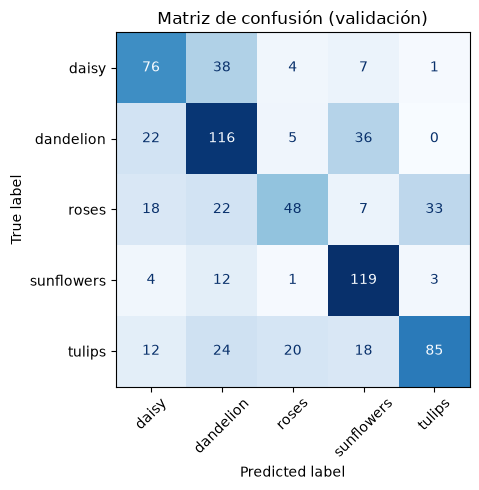

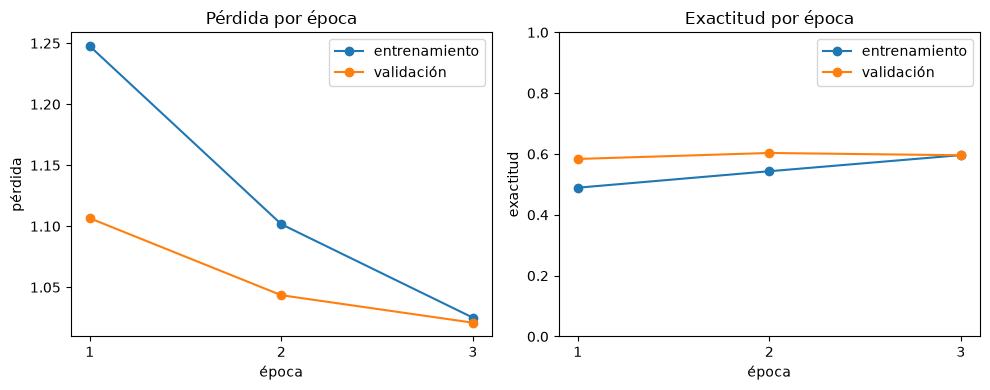

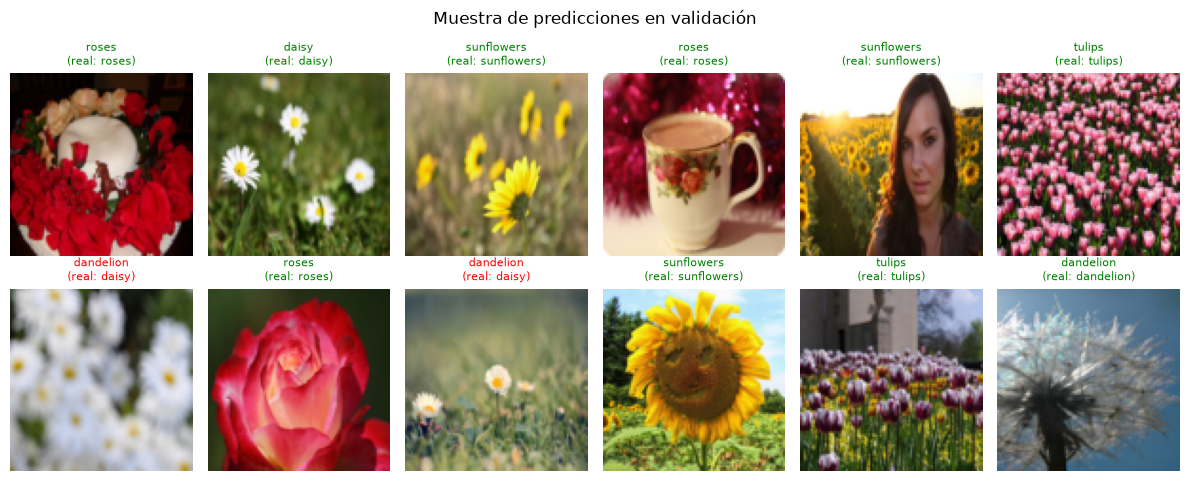

In [6]:
import csv

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix

# 1. Predicciones del mejor punto de control sobre la partición de validación (datos no usados para entrenar).
mejor_modelo = CnnFlores.load_from_checkpoint(mejor.best_model_path, map_location="cpu").eval()
reales, predichas, imagenes = [], [], []
with torch.no_grad():
    for x, y in datos.val_dataloader():
        predichas += mejor_modelo(x).argmax(dim=1).tolist()
        reales += y.tolist()
        imagenes += list(x)
reales, predichas = np.array(reales), np.array(predichas)
# La validación está agrupada por clase: la muestra se elige al azar (con semilla) para que sea representativa.
muestra = np.random.default_rng(SEED).choice(len(reales), size=12, replace=False)

# 2. Exactitud y reporte por clase.
print(f"exactitud en validación: {accuracy_score(reales, predichas):.3f} ({len(reales)} imágenes)")
print(classification_report(reales, predichas, target_names=CLASES, digits=3, zero_division=0))

# 3. Matriz de confusión.
fig, eje = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(reales, predichas), display_labels=CLASES).plot(ax=eje, cmap="Blues", xticks_rotation=45, colorbar=False)
eje.set_title("Matriz de confusión (validación)")
plt.tight_layout()
plt.show()

# 4. Curvas de pérdida y exactitud por época, desde el CSVLogger.
with open(registro.experiment.metrics_file_path) as f:
    filas = list(csv.DictReader(f))


def serie(nombre: str) -> tuple[list[int], list[float]]:
    puntos = [(int(fila["epoch"]), float(fila[nombre])) for fila in filas if fila.get(nombre)]
    return [e + 1 for e, _ in puntos], [v for _, v in puntos]


fig, (eje_perdida, eje_exactitud) = plt.subplots(1, 2, figsize=(10, 4))
for nombre, etiqueta_curva in (("perdida_ent", "entrenamiento"), ("perdida_val", "validación")):
    eje_perdida.plot(*serie(nombre), marker="o", label=etiqueta_curva)
for nombre, etiqueta_curva in (("exactitud_ent", "entrenamiento"), ("exactitud_val", "validación")):
    eje_exactitud.plot(*serie(nombre), marker="o", label=etiqueta_curva)
eje_perdida.set(title="Pérdida por época", xlabel="época", ylabel="pérdida")
eje_exactitud.set(title="Exactitud por época", xlabel="época", ylabel="exactitud", ylim=(0, 1))
for eje in (eje_perdida, eje_exactitud):
    eje.set_xticks(range(1, MAX_EPOCHS + 1))
    eje.legend()
plt.tight_layout()
plt.show()

# 5. Muestra de predicciones (verde = acierto, rojo = error).
fig, ejes = plt.subplots(2, 6, figsize=(12, 5))
media, desviacion = torch.tensor(MEDIA).view(3, 1, 1), torch.tensor(DESVIACION).view(3, 1, 1)
for i, eje in zip(muestra, ejes.ravel()):
    eje.imshow((imagenes[i] * desviacion + media).clamp(0, 1).permute(1, 2, 0))
    acierto = predichas[i] == reales[i]
    eje.set_title(f"{CLASES[predichas[i]]}\n(real: {CLASES[reales[i]]})", fontsize=8, color="green" if acierto else "red")
    eje.axis("off")
plt.suptitle("Muestra de predicciones en validación")
plt.tight_layout()
plt.show()